In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

2. Membaca Dataset dan Melihat Isinya.

In [3]:

df = pd.read_csv('/content/data.csv')

df.columns = df.columns.str.strip()

print("Ukuran dataset:", df.shape)
display(df.head())

df.info()


Ukuran dataset: (294, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,28,1,2,130,132,0,2,185,0,0.0,?,?,?,0
1,29,1,2,120,243,0,0,160,0,0.0,?,?,?,0
2,29,1,2,140,?,0,0,170,0,0.0,?,?,?,0
3,30,0,1,170,237,0,1,170,0,0.0,?,?,6,0
4,31,0,2,100,219,0,1,150,0,0.0,?,?,?,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 294 entries, 0 to 293
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       294 non-null    int64  
 1   sex       294 non-null    int64  
 2   cp        294 non-null    int64  
 3   trestbps  294 non-null    object 
 4   chol      294 non-null    object 
 5   fbs       294 non-null    object 
 6   restecg   294 non-null    object 
 7   thalach   294 non-null    object 
 8   exang     294 non-null    object 
 9   oldpeak   294 non-null    float64
 10  slope     294 non-null    object 
 11  ca        294 non-null    object 
 12  thal      294 non-null    object 
 13  num       294 non-null    int64  
dtypes: float64(1), int64(4), object(9)
memory usage: 32.3+ KB


3. Mengecek nilai yang bermasalah

In [4]:

print(df.isnull().sum())
print("\nJumlah tanda '?':")
print((df == '?').sum())


age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64

Jumlah tanda '?':
age           0
sex           0
cp            0
trestbps      1
chol         23
fbs           8
restecg       1
thalach       1
exang         1
oldpeak       0
slope       190
ca          291
thal        266
num           0
dtype: int64


4. Membersihkan nilai yang tidak tersedia

In [5]:

df = df.replace('?', np.nan)

for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print(df.isnull().sum())


age           0
sex           0
cp            0
trestbps      1
chol         23
fbs           8
restecg       1
thalach       1
exang         1
oldpeak       0
slope       190
ca          291
thal        266
num           0
dtype: int64


5. Mengisi nilai kosong

In [6]:

X = df.drop(columns=['num'])
y = df['num']

imputer = SimpleImputer(strategy='median')
X = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)

print("Jumlah data kosong:", X.isnull().sum().sum())
display(X.head())


Jumlah data kosong: 0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,28.0,1.0,2.0,130.0,132.0,0.0,2.0,185.0,0.0,0.0,2.0,0.0,6.0
1,29.0,1.0,2.0,120.0,243.0,0.0,0.0,160.0,0.0,0.0,2.0,0.0,6.0
2,29.0,1.0,2.0,140.0,243.0,0.0,0.0,170.0,0.0,0.0,2.0,0.0,6.0
3,30.0,0.0,1.0,170.0,237.0,0.0,1.0,170.0,0.0,0.0,2.0,0.0,6.0
4,31.0,0.0,2.0,100.0,219.0,0.0,1.0,150.0,0.0,0.0,2.0,0.0,6.0


6. Membagi data training dan testing

In [7]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])


Jumlah data training: 235
Jumlah data testing: 59


7. Membuat model Logistic Regression

In [8]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(X_train_scaled, y_train)

y_pred_lr = model_lr.predict(X_test_scaled)


8. Evaluasi Logistic Regression

Accuracy: 0.8305084745762712

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87        38
           1       0.79      0.71      0.75        21

    accuracy                           0.83        59
   macro avg       0.82      0.80      0.81        59
weighted avg       0.83      0.83      0.83        59



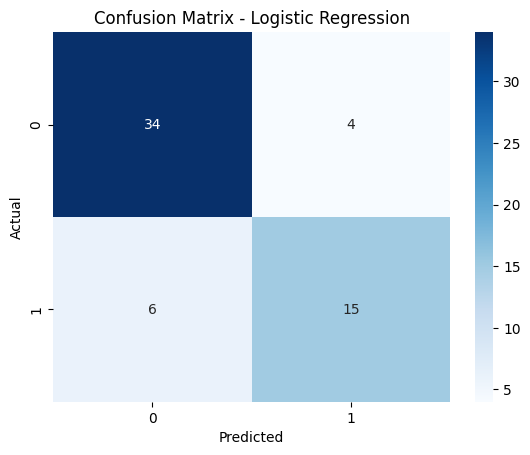

In [9]:

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

cm = confusion_matrix(y_test, y_pred_lr)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()


9. Membuat model Decision Tree

In [10]:

model_dt = DecisionTreeClassifier(random_state=42)
model_dt.fit(X_train, y_train)

y_pred_dt = model_dt.predict(X_test)


10. Evaluasi Decision Tree

Accuracy: 0.7457627118644068

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.76      0.79        38
           1       0.62      0.71      0.67        21

    accuracy                           0.75        59
   macro avg       0.73      0.74      0.73        59
weighted avg       0.76      0.75      0.75        59



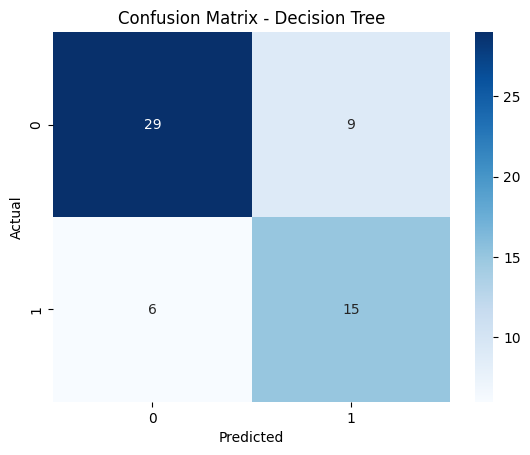

In [11]:

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

cm = confusion_matrix(y_test, y_pred_dt)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Decision Tree')
plt.show()


11. Membuat model Random Forest

In [12]:

model_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model_rf.fit(X_train, y_train)

y_pred_rf = model_rf.predict(X_test)


12. Evaluasi Random Forest

Accuracy: 0.864406779661017

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.89      0.89        38
           1       0.81      0.81      0.81        21

    accuracy                           0.86        59
   macro avg       0.85      0.85      0.85        59
weighted avg       0.86      0.86      0.86        59



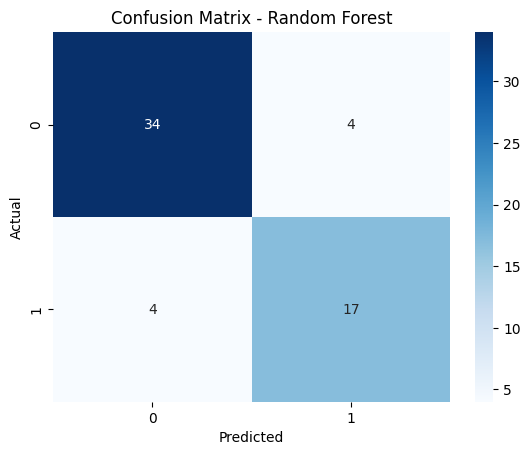

In [13]:

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

cm = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Random Forest')
plt.show()


13. Perbandingan model klasifikasi

In [14]:

hasil = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf)
    ],
    'F1-Score': [
        0.75,
        0.67,
        0.81
    ]
})

hasil = hasil.sort_values(by='Accuracy', ascending=False)
display(hasil.round(4))


,Model,Accuracy,F1-Score
2,Random Forest,0.8644,0.81
0,Logistic Regression,0.8305,0.75
1,Decision Tree,0.7458,0.67


14. Memperbarui tabel perbandingan

In [15]:

from sklearn.metrics import f1_score

hasil = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf)
    ],
    'F1-Score': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf)
    ]
})

hasil = hasil.sort_values(by='Accuracy', ascending=False)
display(hasil.round(4))


,Model,Accuracy,F1-Score
2,Random Forest,0.8644,0.8095
0,Logistic Regression,0.8305,0.7500
1,Decision Tree,0.7458,0.6667


## Kesimpulan

Berdasarkan hasil pengujian tiga model klasifikasi, Random Forest memperoleh hasil terbaik dengan accuracy sebesar 86,44% dan F1-score kelas 1 sebesar 0,8095. Logistic Regression memperoleh accuracy sebesar 83,05% dan F1-score sebesar 0,7500, sedangkan Decision Tree memperoleh accuracy sebesar 74,58% dan F1-score sebesar 0,6667.

Dari hasil tersebut, Random Forest menjadi model dengan performa terbaik pada dataset yang digunakan. Model ini menghasilkan prediksi yang lebih baik dibandingkan dua model lainnya pada data testing. Namun, hasil evaluasi ini hanya berlaku pada pembagian data yang digunakan dan belum menjamin performa yang sama pada data baru.